<a href="https://colab.research.google.com/github/michellecarizona/heart_disease_practice/blob/main/heart_disease_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd              # For working with data tables (like spreadsheets)
import matplotlib.pyplot as plt  # For creating plots and visualizations
import seaborn as sns            # For making plots look nicer and easier
from sklearn.model_selection import train_test_split  # To split data into training and testing sets
from sklearn.linear_model import LogisticRegression   # For building the classification model
from sklearn.metrics import accuracy_score            # To check how well the model performs
from sklearn.metrics import confusion_matrix          # To create a confusion matrix for evaluation
from sklearn.preprocessing import StandardScaler      # To standardize numerical data

In [2]:
data = pd.read_csv('https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/heart-disease-UCI.csv')

In [3]:
print("First 5 rows of the dataset:")
print(data.head())

First 5 rows of the dataset:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  


In [4]:
print("\nChecking for missing values:")
print(data.isnull().sum())  # Shows how many missing values per column


Checking for missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


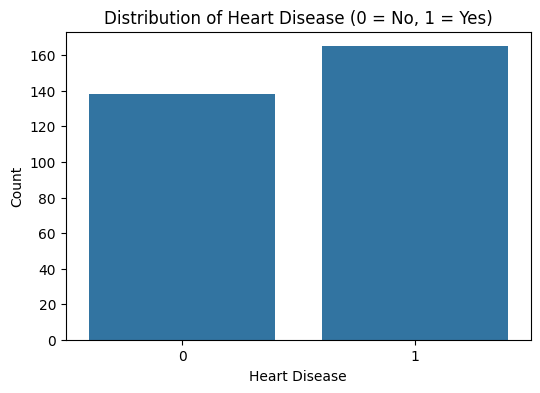

In [5]:
plt.figure(figsize=(6, 4))  # Set the size of the plot
sns.countplot(x='target', data=data)  # Create a bar plot for the target column
plt.title('Distribution of Heart Disease (0 = No, 1 = Yes)')  # Add a title
plt.xlabel('Heart Disease')  # Label the x-axis
plt.ylabel('Count')  # Label the y-axis
plt.show()  # Display the plot

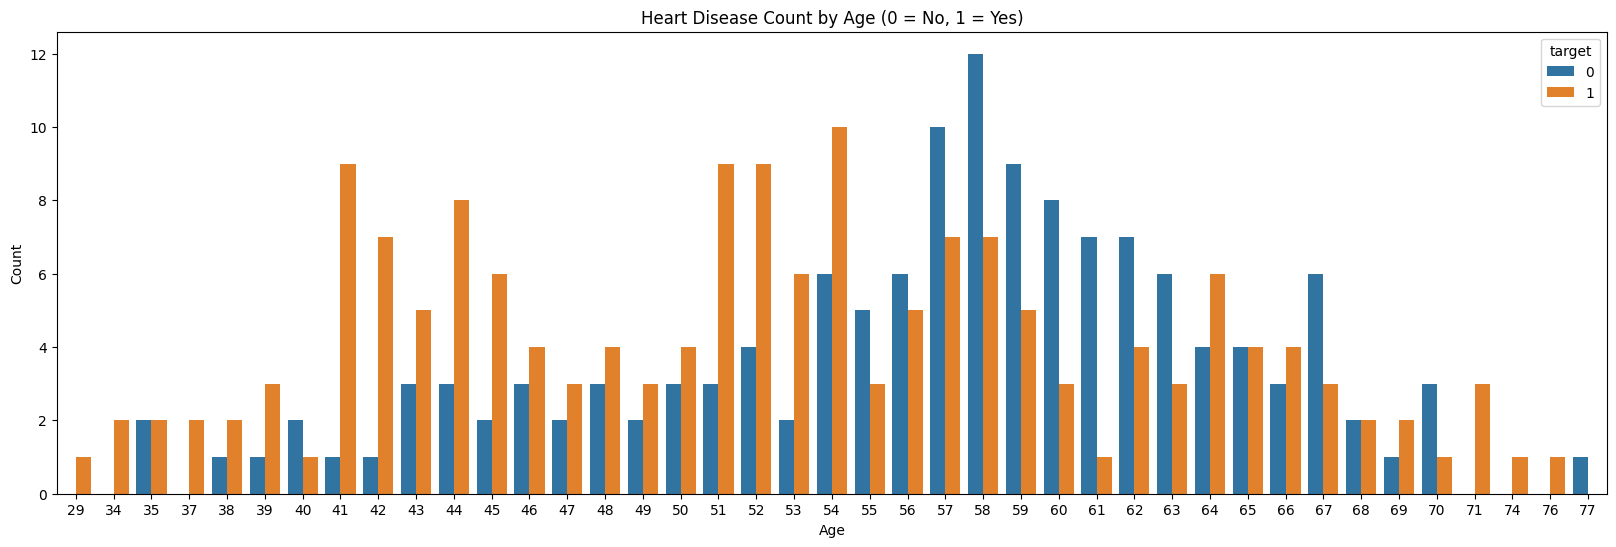

In [12]:
plt.figure(figsize=(20, 6))  # Set the size of the plot
sns.countplot(x='age', hue='target', data=data)  # Create a bar plot for the target column
plt.title('Heart Disease Count by Age (0 = No, 1 = Yes)')  # Add a title
plt.xlabel('Age')  # Label the x-axis
plt.ylabel('Count')  # Label the y-axis
plt.show()  # Display the plot

created a new graph that showed the relationship between age and number of people with/ without heart disease

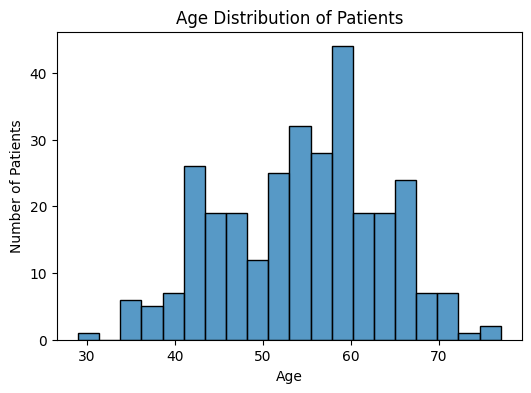

In [18]:
# Visualize the age distribution of patients
# This helps us understand the age range of patients in the dataset
plt.figure(figsize=(6, 4))  # Set the size of the plot
sns.histplot(data['age'], bins=20)  # Create a histogram for the age column
plt.title('Age Distribution of Patients')  # Add a title
plt.xlabel('Age')  # Label the x-axis
plt.ylabel('Number of Patients')  # Label the y-axis
plt.show()  # Display the plot

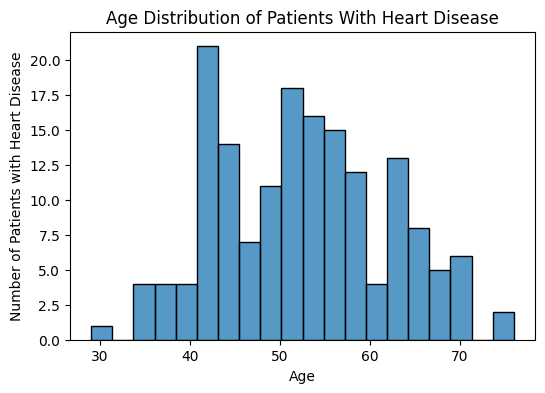

In [52]:
plt.figure(figsize=(6, 4))  # Set the size of the plot

# Step 1: Filter the dataset to keep only rows where target is 1 (has heart disease)
filtered_data = data[data['target'] == 1]

# Step 2: Pass the filtered data into histplot using proper arguments
sns.histplot(x='age', data=filtered_data,  bins=20)

plt.title('Age Distribution of Patients With Heart Disease')  # Updated title
plt.xlabel('Age')  # Label the x-axis
plt.ylabel('Number of Patients with Heart Disease')  # Label the y-axis
plt.show()  # Display the plot

created a new graph that shows the relationship between age and the patients with heart disease

In [20]:
scaler = StandardScaler()  # Create a scaler object
X_scaled = scaler.fit_transform(X)  # Scale all features to have mean=0, std=1

In [42]:
# Split the data into training and testing sets
# Training data (80%) is used to train the model, testing data (20%) to evaluate it
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [43]:
model = LogisticRegression()  # Create a Logistic Regression model
model.fit(X_train, y_train)  # Train the model on the training data

LogisticRegression()

In [44]:
y_pred = model.predict(X_test)  # Predict the target values for test data

In [45]:
# Accuracy is the percentage of correct predictions
accuracy = accuracy_score(y_test, y_pred)  # Compare actual vs. predicted values
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")  # Print accuracy as a percentage


Model Accuracy: 85.25%


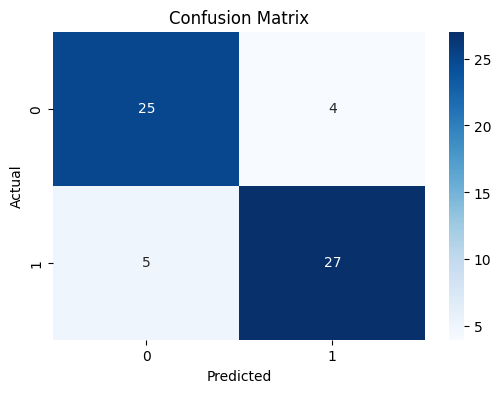

In [46]:
cm = confusion_matrix(y_test, y_pred)  # Create a confusion matrix
plt.figure(figsize=(6, 4))  # Set the size of the plot
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')  # Create a heatmap of the confusion matrix
plt.title('Confusion Matrix')  # Add a title
plt.xlabel('Predicted')  # Label the x-axis
plt.ylabel('Actual')  # Label the y-axis
plt.show()  # Display the plot